In [148]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy import signal

Cortesia de Thomas Andrade


In [149]:
def matrixCreator(raw, pixelsX, pixelsY):
    matrix = []
    for i in range(0, len(raw), pixelsX*pixelsY):
        blank = np.zeros((pixelsX, pixelsY))
        for j in range(0, pixelsX):
            for k in range(0, pixelsY):
                blank[j, k] = raw[k + pixelsX*j + i]
        matrix.append(blank) 
    return matrix

def dataCreator(filename, pixelsX, pixelsY):
    raw_array = np.fromfile(filename, dtype = "float32")
    matrix = matrixCreator(raw_array, pixelsX, pixelsY)
    return matrix

def imageCreator(data, COLValue):
    image = []
    mean = 0
    for i in range(0, COLValue + 1):
        mean += data[i]
    mean = mean/(COLValue + 1)
    image.append(mean)  
    return image[0]

In [150]:

COL = 1 # Cambiar por el tipo de adquisición.
pixelsX = 256 
pixelsY = 256

In [151]:
#sample = dataCreator(directorio, pixelsX, pixelsY)
#image = imageCreator(sample, COL)
#plt.imshow(image, cmap='gray')

___

Retrieval algoritm

<hr style="border: none; border-top: 2px dotted #808080; height: 0;">

A. Single-Mask DPC Configuration

Atenuation and DPC 

PARAMETERS:
Distance Source-Mask:60cm
Distance Mask-Detector:60cm
Focal Length:7um
Events:2000000000
Energy:30Kev


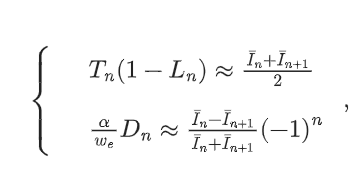 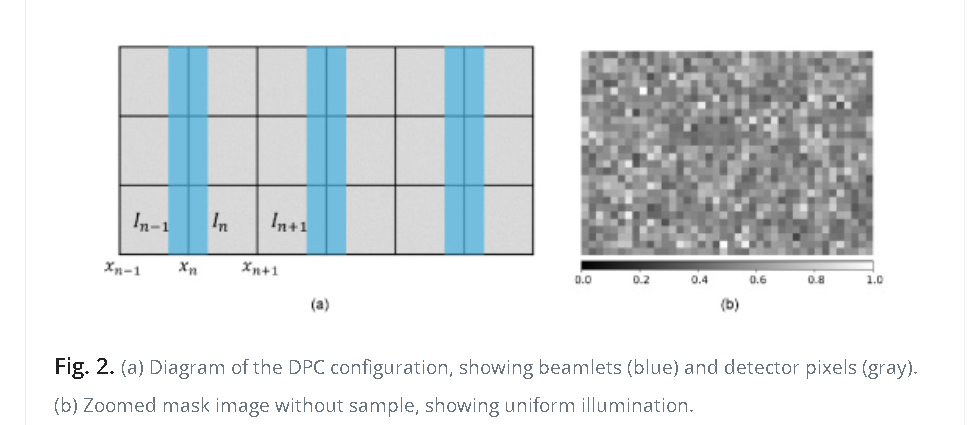

FLAT FIELD  DPC

In [152]:
# Cargar los datos del Flat Field
ff_dpc_dir = None

sample = dataCreator(ff_dpc_dir, pixelsX, pixelsY)
ff_image = imageCreator(sample, COL)

# Crear una figura con dos paneles lado a lado (1 fila, 2 columnas)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))

# 1. Gráfica izquierda: Imagen completa de Flat Field
im1 = ax1.imshow(ff_image, cmap='gray')
ax1.set_title("Flat Field Completo")
ax1.set_xlabel("Columnas de Píxeles")
ax1.set_ylabel("Filas de Píxeles")
fig.colorbar(im1, ax=ax1, fraction=0.046, pad=0.04)

# 2. Gráfica derecha: Zoom en las primeras 10 columnas y 10 filas (índices 0 al 10)
# Usamos ff_image[:10, :10] para recortar la matriz
zoom_region = ff_image[:10, :10]
im2 = ax2.imshow(zoom_region, cmap='gray', interpolation='nearest')
ax2.set_title("Zoom: Primeras 10x10 Píxeles")
ax2.set_xlabel("Columnas (0 - 9)")
ax2.set_ylabel("Filas (0 - 9)")

# Configurar los ticks para que muestren exactamente los números de píxel del 0 al 9
ax2.set_xticks(np.arange(10))
ax2.set_yticks(np.arange(10))

# Opcional: Mostrar la cuadrícula (grid) en el zoom para distinguir bien los píxeles individuales
ax2.grid(True, which='both', color='red', linestyle='-', linewidth=0.5, alpha=0.5)
fig.colorbar(im2, ax=ax2, fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

AttributeError: 'NoneType' object has no attribute 'flush'

In [ ]:
def DPC_config(sample_image, ff_image, pixelsX, pixelsY):
    """
    sample_image : imagen con la muestra
    ff_image     : flat field
    pixelsX      : número de columnas
    pixelsY      : número de filas

    Devuelve:
        att_image : (pixelsY, pixelsX//2)
        dpc_image : (pixelsY, pixelsX//2)
    """

    # Intensidad normalizada
    I_bar = sample_image.astype(np.float32) / (
        ff_image.astype(np.float32) + 1e-12
    )

    att_image = np.zeros((pixelsY, pixelsX // 2), dtype=np.float32)
    dpc_image = np.zeros((pixelsY, pixelsX // 2), dtype=np.float32)

    new_col = 0

    for pixel in range(0, pixelsX, 2):

        In = I_bar[:, pixel]
        In1 = I_bar[:, pixel + 1]

        # Att
        att_image[:, new_col] = (In + In1) / 2.0

        # DPC
        denominator = In + In1
        denominator = np.where(denominator == 0, 1e-12, denominator)

        dpc_image[:, new_col] = ((In - In1) / denominator) * ((-1)**pixel)

        new_col += 1

    return att_image, dpc_image

CARGA DPC

------------------------

Dark Field


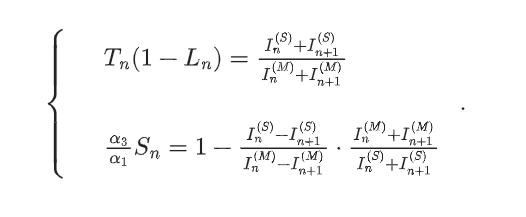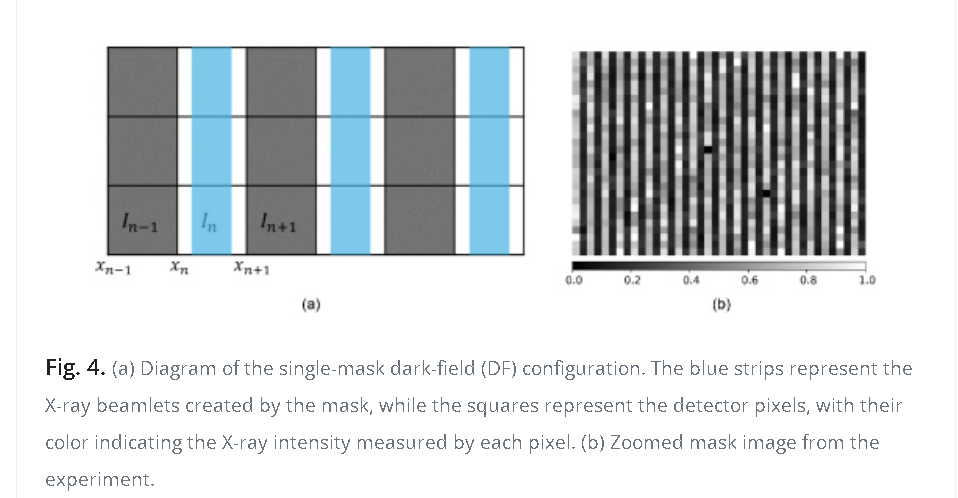

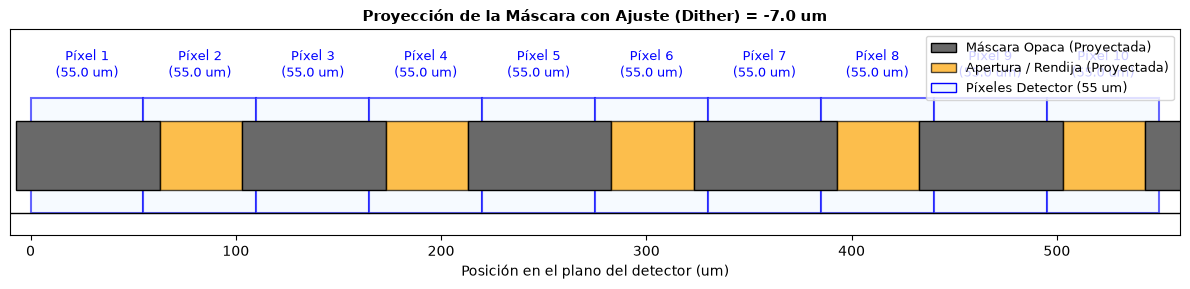

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Configuración de la figura
fig, ax = plt.subplots(figsize=(12, 3))

# Parámetros geométricos (en um)
pixel_pitch = 55.0
mask_pitch_proj = 110.0  # 55 um * M(2.0)
mask_aperture_proj = 40.0 # 20 um * M(2.0)
mask_opaque_proj = mask_pitch_proj - mask_aperture_proj

# Parámetro de ajuste / desplazamiento (dither) en micras
# Puedes modificar este valor para ver cómo se corre todo el patrón de la máscara
ajuste_dither = -3.5 * 2

# Dibujar píxeles del detector
num_pixels = 10
for i in range(num_pixels):
    rect_pixel = patches.Rectangle((i * pixel_pitch, 0), pixel_pitch, 1, 
                                   linewidth=1.5, edgecolor='blue', facecolor='aliceblue', alpha=0.6)
    ax.add_patch(rect_pixel)
    ax.text(i * pixel_pitch + pixel_pitch/2, 1.15, f'Píxel {i+1}\n({pixel_pitch} um)', 
            ha='center', va='bottom', fontsize=9, color='blue')

# Dibujar máscara proyectada (varios periodos) aplicando el ajuste inicial
current_pos = ajuste_dither
while current_pos < num_pixels * pixel_pitch + mask_pitch_proj:
    # Parte opaca de la máscara
    rect_opaque = patches.Rectangle((current_pos, 0.2), mask_opaque_proj, 0.6, 
                                     linewidth=1, edgecolor='black', facecolor='dimgray')
    ax.add_patch(rect_opaque)
    
    # Apertura de la máscara
    rect_aperture = patches.Rectangle((current_pos + mask_opaque_proj, 0.2), mask_aperture_proj, 0.6, 
                                       linewidth=1, edgecolor='black', facecolor='orange', alpha=0.7)
    ax.add_patch(rect_aperture)
    
    current_pos += mask_pitch_proj

# Ajustes de los ejes
ax.set_xlim(-10, num_pixels * pixel_pitch + 10)
ax.set_ylim(-0.2, 1.6)
ax.axhline(0, color='black', linewidth=1)
ax.set_yticks([])
ax.set_xlabel('Posición en el plano del detector (um)', fontsize=10)
ax.set_title(f'Proyección de la Máscara con Ajuste (Dither) = {ajuste_dither} um', fontsize=11, weight='bold')

# Leyenda manual
from matplotlib.lines import Line2D
legend_elements = [
    patches.Patch(facecolor='dimgray', edgecolor='black', label='Máscara Opaca (Proyectada)'),
    patches.Patch(facecolor='orange', edgecolor='black', alpha=0.7, label='Apertura / Rendija (Proyectada)'),
    patches.Patch(facecolor='aliceblue', edgecolor='blue', label='Píxeles Detector (55 um)')
]
ax.legend(handles=legend_elements, loc='upper right', fontsize=9)

plt.tight_layout()
plt.show()

Flat Field DF


Posiciones cargadas: [0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100, 110]
Forma de la imagen en pos_0: (256, 256)


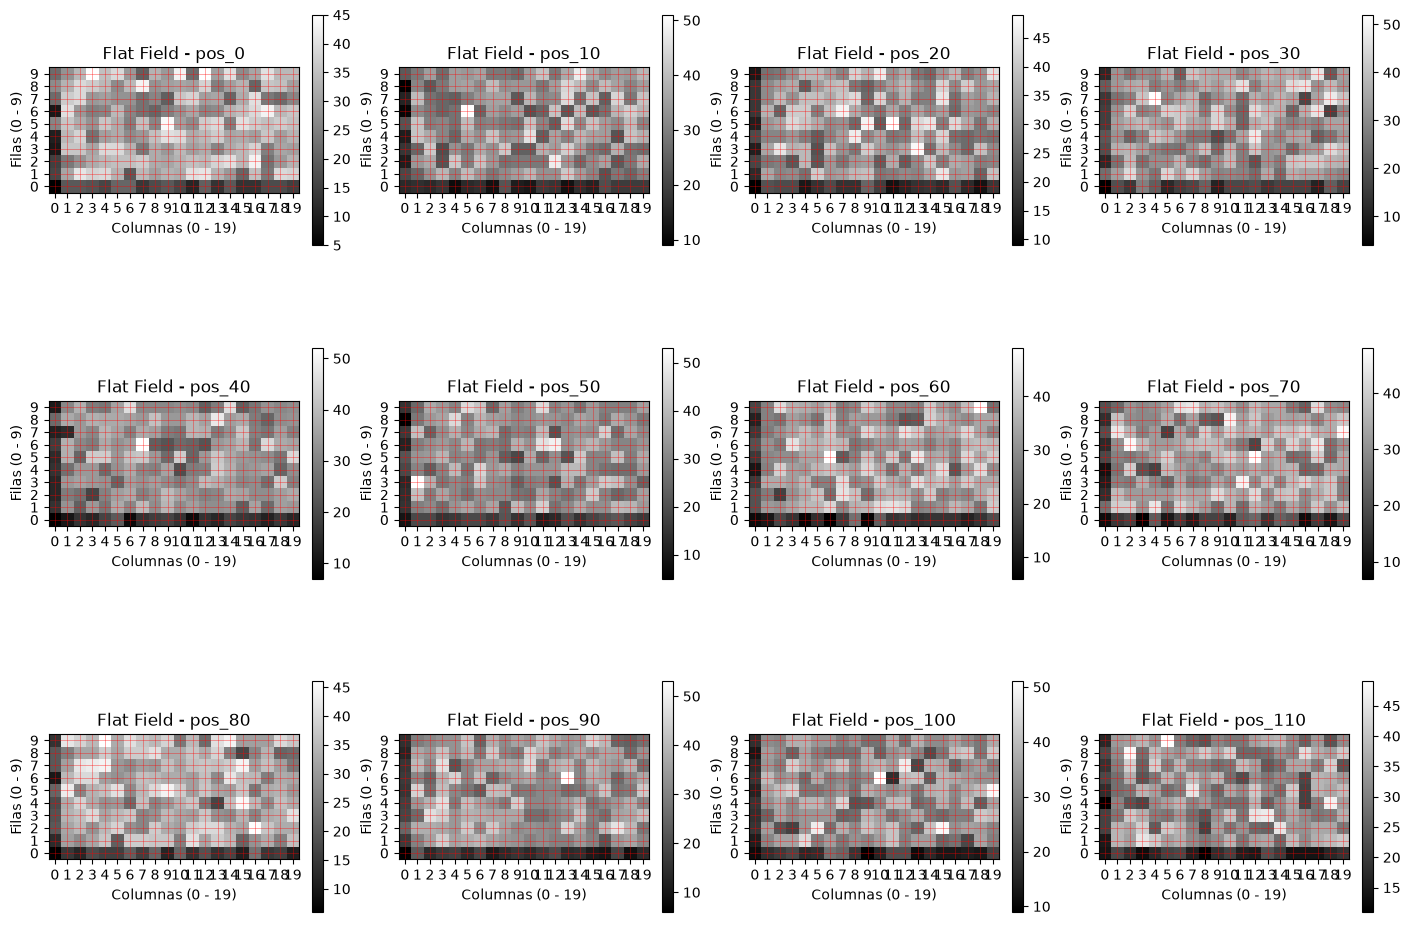

In [ ]:
# Cargar los datos del Flat Field para todas las posiciones
posiciones = range(0, 111, 10)
flat_fields = {}

for x in posiciones:
    ff_dpc_dir = fr"Resultados\DPC o DF\FF\pos_{x}\pos_{x}.raw"
    sample = dataCreator(ff_dpc_dir, pixelsX, pixelsY)
    flat_fields[x] = sample[0]

print("Posiciones cargadas:", list(flat_fields.keys()))
print("Forma de la imagen en pos_0:", flat_fields[0].shape)

# Mostrar solo las primeras 20 columnas y 10 filas
fig, axes = plt.subplots(3, 4, figsize=(14, 10), constrained_layout=True)

for ax, (x, ff_image) in zip(axes.flat, flat_fields.items()):
    zoom_region = ff_image[:10, :20]
    im = ax.imshow(zoom_region, cmap="gray", origin="lower", interpolation="nearest")
    ax.set_title(f"Flat Field - pos_{x}")
    ax.set_xlabel("Columnas (0 - 19)")
    ax.set_ylabel("Filas (0 - 9)")
    ax.set_xticks(np.arange(20))
    ax.set_yticks(np.arange(10))
    ax.grid(True, color="red", linestyle="-", linewidth=0.5, alpha=0.5)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.show()

Forma de la imagen: (256, 256)


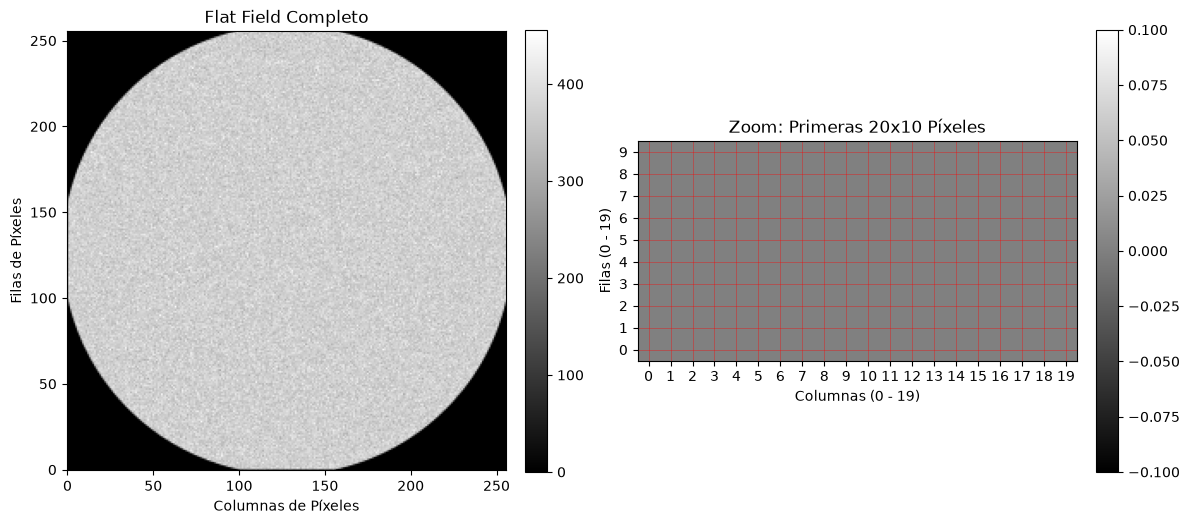

In [153]:
# Cargar los datos del Flat Field
ff_dpc_dir = r"Resultados\DPC o DF\FF\Teorica_corregido_angulo.raw"
sample = dataCreator(ff_dpc_dir, pixelsX, pixelsY)

# Selecciona directamente la matriz 2D del canal deseado (ej. canal 0)
ff_image = sample[0]  # <--- Evita usar imageCreator aquí si te estaba aplanando los datos

# Verificar la forma (shape) de la matriz antes de graficar (debe ser bidimensional: ej. 402, 512)
print("Forma de la imagen:", ff_image.shape)

# Crear la figura con dos paneles
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))

# 1. Gráfica izquierda: Imagen completa de Flat Field
im1 = ax1.imshow(ff_image, cmap='gray', origin='lower')
ax1.set_title("Flat Field Completo")
ax1.set_xlabel("Columnas de Píxeles")
ax1.set_ylabel("Filas de Píxeles")
fig.colorbar(im1, ax=ax1, fraction=0.046, pad=0.04)

# 2. Gráfica derecha: Zoom en las primeras 10 columnas y 10 filas
zoom_region = ff_image[:10, :20]
im2 = ax2.imshow(zoom_region, cmap='gray', interpolation='nearest', origin='lower')
ax2.set_title("Zoom: Primeras 20x10 Píxeles")
ax2.set_xlabel("Columnas (0 - 19)")
ax2.set_ylabel("Filas (0 - 19)")
ax2.set_xticks(np.arange(20))
ax2.set_yticks(np.arange(10))
ax2.grid(True, which='both', color='red', linestyle='-', linewidth=0.5, alpha=0.5)
fig.colorbar(im2, ax=ax2, fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()


<hr style="border: none; border-top: 2px dotted #808080; height: 0;">

B. Single-Mask DF-DPC Configuration

PARAMETERS:
Distance Source-Mask:60cm
Distance Mask-Detector:120cm
Focal Length:7um
Events:2000000000
Energy:10-30Kev


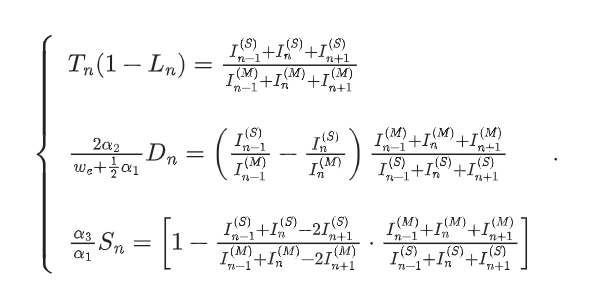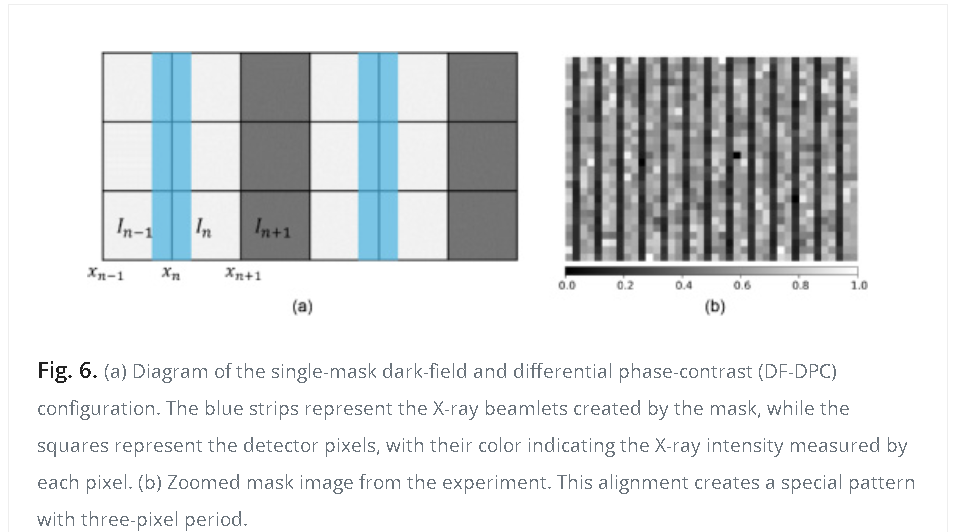

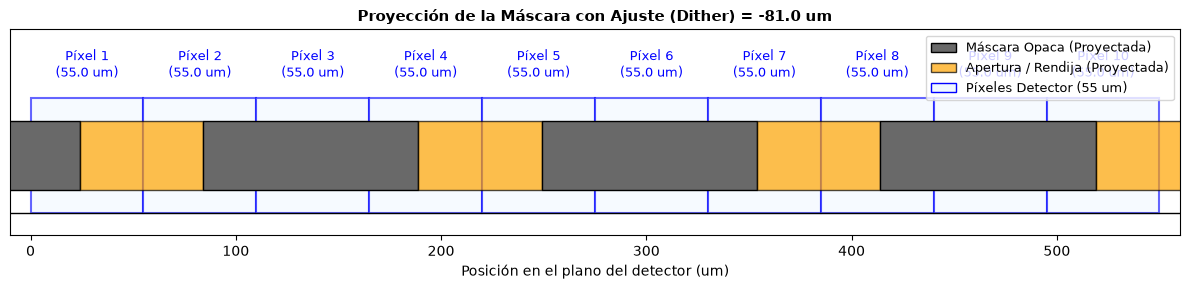

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Configuración de la figura
fig, ax = plt.subplots(figsize=(12, 3))

# Parámetros geométricos (en um)
pixel_pitch = 55.0
mask_pitch_proj = 165.0  # 55 um * M(3.0)
mask_aperture_proj = 60.0 # 20 um * M(3.0)
mask_opaque_proj = mask_pitch_proj - mask_aperture_proj

# Parámetro de ajuste / desplazamiento (dither) en micras
# Puedes modificar este valor para ver cómo se corre todo el patrón de la máscara
ajuste_dither = -27.0 *3

# Dibujar píxeles del detector
num_pixels = 10
for i in range(num_pixels):
    rect_pixel = patches.Rectangle((i * pixel_pitch, 0), pixel_pitch, 1, 
                                   linewidth=1.5, edgecolor='blue', facecolor='aliceblue', alpha=0.6)
    ax.add_patch(rect_pixel)
    ax.text(i * pixel_pitch + pixel_pitch/2, 1.15, f'Píxel {i+1}\n({pixel_pitch} um)', 
            ha='center', va='bottom', fontsize=9, color='blue')

# Dibujar máscara proyectada (varios periodos) aplicando el ajuste inicial
current_pos = ajuste_dither
while current_pos < num_pixels * pixel_pitch + mask_pitch_proj:
    # Parte opaca de la máscara
    rect_opaque = patches.Rectangle((current_pos, 0.2), mask_opaque_proj, 0.6, 
                                     linewidth=1, edgecolor='black', facecolor='dimgray')
    ax.add_patch(rect_opaque)
    
    # Apertura de la máscara
    rect_aperture = patches.Rectangle((current_pos + mask_opaque_proj, 0.2), mask_aperture_proj, 0.6, 
                                       linewidth=1, edgecolor='black', facecolor='orange', alpha=0.7)
    ax.add_patch(rect_aperture)
    
    current_pos += mask_pitch_proj

# Ajustes de los ejes
ax.set_xlim(-10, num_pixels * pixel_pitch + 10)
ax.set_ylim(-0.2, 1.6)
ax.axhline(0, color='black', linewidth=1)
ax.set_yticks([])
ax.set_xlabel('Posición en el plano del detector (um)', fontsize=10)
ax.set_title(f'Proyección de la Máscara con Ajuste (Dither) = {ajuste_dither} um', fontsize=11, weight='bold')

# Leyenda manual
from matplotlib.lines import Line2D
legend_elements = [
    patches.Patch(facecolor='dimgray', edgecolor='black', label='Máscara Opaca (Proyectada)'),
    patches.Patch(facecolor='orange', edgecolor='black', alpha=0.7, label='Apertura / Rendija (Proyectada)'),
    patches.Patch(facecolor='aliceblue', edgecolor='blue', label='Píxeles Detector (55 um)')
]
ax.legend(handles=legend_elements, loc='upper right', fontsize=9)

plt.tight_layout()
plt.show()

Flat Field (UNICO)



Posiciones cargadas: [0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100, 110]
Forma de la imagen en pos_0: (256, 256)


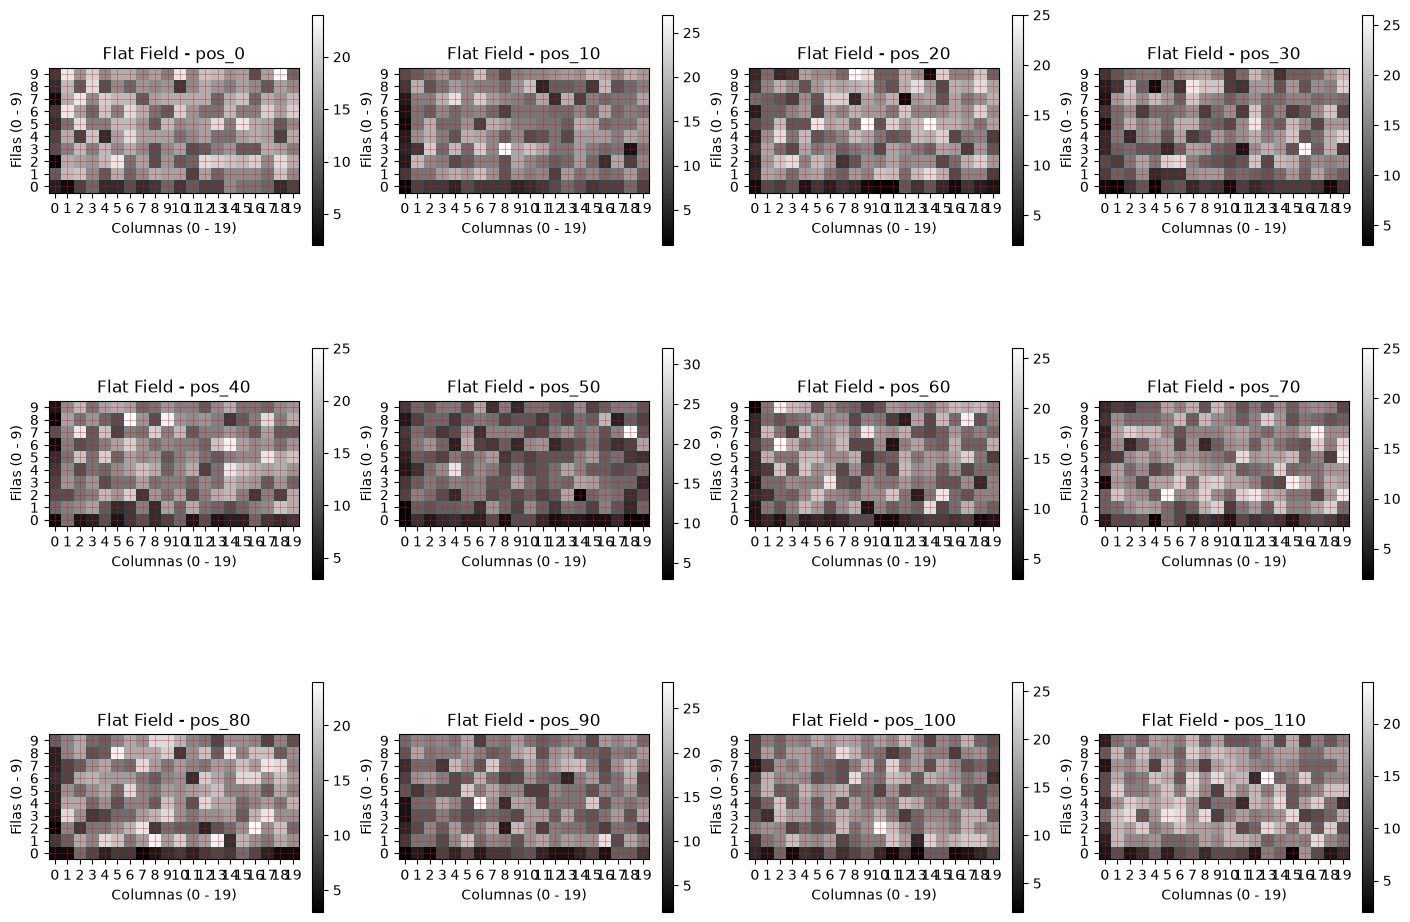

In [ ]:
# Cargar los datos del Flat Field para todas las posiciones
posiciones = range(0, 111, 10)
flat_fields = {}

for x in posiciones:
    ff_dpc_dir = fr"Resultados\DPCyDF\FF\pos_{x}\pos_{x}.raw"
    sample = dataCreator(ff_dpc_dir, pixelsX, pixelsY)
    flat_fields[x] = sample[0]

print("Posiciones cargadas:", list(flat_fields.keys()))
print("Forma de la imagen en pos_0:", flat_fields[0].shape)

# Mostrar solo las primeras 20 columnas y 10 filas
fig, axes = plt.subplots(3, 4, figsize=(14, 10), constrained_layout=True)

for ax, (x, ff_image) in zip(axes.flat, flat_fields.items()):
    zoom_region = ff_image[:10, :20]
    im = ax.imshow(zoom_region, cmap="gray", origin="lower", interpolation="nearest")
    ax.set_title(f"Flat Field - pos_{x}")
    ax.set_xlabel("Columnas (0 - 19)")
    ax.set_ylabel("Filas (0 - 9)")
    ax.set_xticks(np.arange(20))
    ax.set_yticks(np.arange(10))
    ax.grid(True, color="red", linestyle="-", linewidth=0.5, alpha=0.5)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.show()

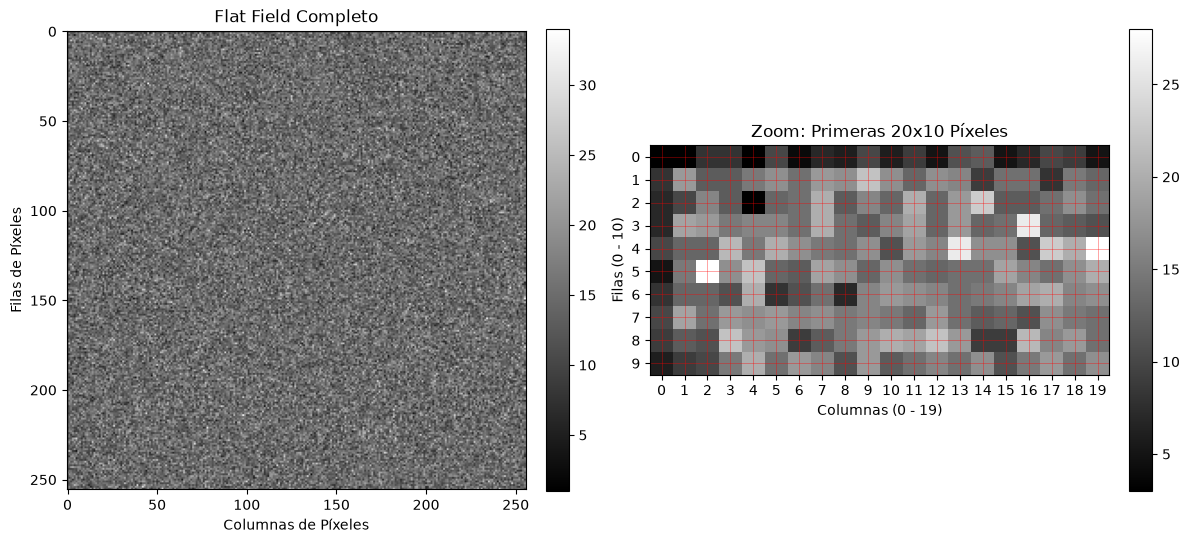

In [ ]:
# Cargar los datos del Flat Field
ff_dpc_dir = r"Resultados\DPCyDF\FF\TEORICO_Corregido_DFyDPC.raw"

sample = dataCreator(ff_dpc_dir, pixelsX, pixelsY)
ff_image = imageCreator(sample, COL)
# Crear una figura con dos paneles lado a lado (1 fila, 2 columnas)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))

# 1. Gráfica izquierda: Imagen completa de Flat Field
im1 = ax1.imshow(ff_image, cmap='gray')
ax1.set_title("Flat Field Completo")
ax1.set_xlabel("Columnas de Píxeles")
ax1.set_ylabel("Filas de Píxeles")
fig.colorbar(im1, ax=ax1, fraction=0.046, pad=0.04)

# 2. Gráfica derecha: Zoom estricto en las primeras 20 columnas y 20 filas (0 al 19)
zoom_region = ff_image[:10, :20]
im2 = ax2.imshow(zoom_region, cmap='gray', interpolation='nearest')
ax2.set_title("Zoom: Primeras 20x10 Píxeles")
ax2.set_xlabel("Columnas (0 - 19)")
ax2.set_ylabel("Filas (0 - 10)")

# Configurar los ticks exactamente de 0 a 9
ax2.set_xticks(np.arange(20))
ax2.set_yticks(np.arange(10))

# Cuadrícula para examinar cada píxel individual
ax2.grid(True, which='both', color='red', linestyle='-', linewidth=0.5, alpha=0.5)
fig.colorbar(im2, ax=ax2, fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

---

Resultados

NameError: name 'imagen_attenuacion' is not defined

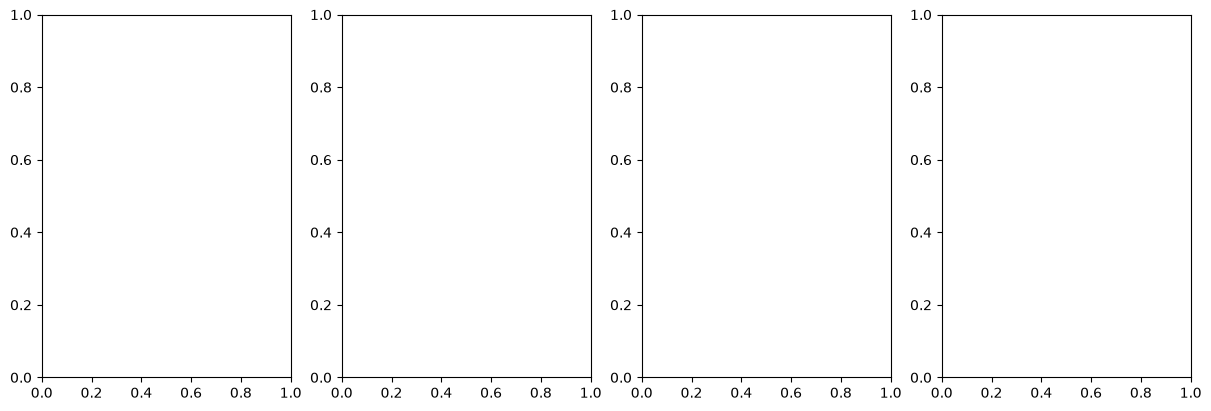

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(12, 4), constrained_layout=True)

imagenes = [imagen_attenuacion, phase_grad, phase, dark_field]
titulos = ["Atenuación", "Diferencial de fase", "Fase", "Dark Field"]

for ax, img, titulo in zip(axes, imagenes, titulos):
    ax.imshow(img, cmap="gray")
    ax.set_title(titulo)
    ax.axis("off")
    ax.set_aspect("equal", adjustable="box")

plt.show()